# Final evaluation on the independent seed43 test set

Frozen GNN, descriptor MLP and canonical Transformer checkpoints use training seeds 202601--202605. Each is evaluated on the same 2,000 test structures.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'))
from paper_style import COLORS, configure_paper_style, style_axis, save_dual
configure_paper_style()
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'checkpoints/gnn').is_dir())
DATA = ROOT / 'results/source_data/final_evaluation'
OUT = ROOT / 'results/figures/seed43_final_evaluation'
OUT.mkdir(parents=True, exist_ok=True)
SEEDS = tuple(range(202601,202606))
LOSS_COLORS = ('blue','red','green','purple','amber')
def publish(fig, stem, *, tight=False):
    save_dual(fig, stem, tight=tight)
    fig.savefig(stem.with_suffix('.pdf'), dpi=600, facecolor='white')
    display(Image(filename=str(stem.with_suffix('.png')), width=850))
    plt.close(fig)


## Prediction checks and metrics


In [2]:
predictions = {}
rows = []
for model in ['gnn','mlp','transformer']:
    for seed in SEEDS:
        folder = DATA / model
        suffix = '.csv' if model == 'transformer' else '.npz'
        path = next(p for p in folder.rglob('*') if 'prediction' in p.name and str(seed) in p.name and p.suffix == suffix and ('seed43' in str(p) or 'final_test_seed43' in str(p)))
        if suffix == '.npz':
            with np.load(path, allow_pickle=True) as d:
                true, pred = 10**d['y_true_log'], 10**d['y_pred_log']
                ids = d['sample_id'].astype(str) if 'sample_id' in d else None
        else:
            frame = pd.read_csv(path)
            true, pred, ids = frame['true'].to_numpy(), frame.pred.to_numpy(), frame.base_name.to_numpy()
        assert len(true)==2000 and np.all(np.isfinite(pred)) and np.all(pred>0)
        predictions[model,seed] = (true,pred,ids)
        error = pred-true
        rows.append(dict(model=model,seed=seed,MAPE=float((np.abs(error)/true*100).mean()),RMSE=float(np.sqrt(np.mean(error**2))),MAE=float(np.abs(error).mean()),R2=float(1-np.sum(error**2)/np.sum((true-true.mean())**2))))
reference = predictions['mlp',202601]
for true,pred,ids in predictions.values():
    np.testing.assert_allclose(true,reference[0],rtol=1e-6)
    if ids is not None: np.testing.assert_array_equal(ids,reference[2])
metrics = pd.DataFrame(rows)
summary = metrics.groupby('model')[['MAPE','RMSE','MAE','R2']].agg(['mean','std'])
for model,mean,sd in [('mlp',2.2117,.1060),('gnn',.4238,.0905),('transformer',.3679,.0343)]:
    np.testing.assert_allclose(summary.loc[model, 'MAPE'].to_numpy(),[mean,sd],atol=5e-5,rtol=0)
metrics.to_csv(DATA/'seed43_per_seed_metrics.csv',index=False)
summary.to_csv(DATA/'seed43_summary.csv')
print(summary.to_string())


                 MAPE                RMSE                 MAE                  R2         
                 mean       std      mean       std      mean       std      mean      std
model                                                                                     
gnn          0.423767  0.090469  1.080466  0.331984  0.323900  0.097677  0.999837  0.00010
mlp          2.211654  0.106048  5.394152  0.517105  1.670467  0.100666  0.996188  0.00074
transformer  0.367908  0.034343  1.014471  0.113817  0.275748  0.028330  0.999865  0.00003


## GNN training histories (Supplementary Fig. S17)


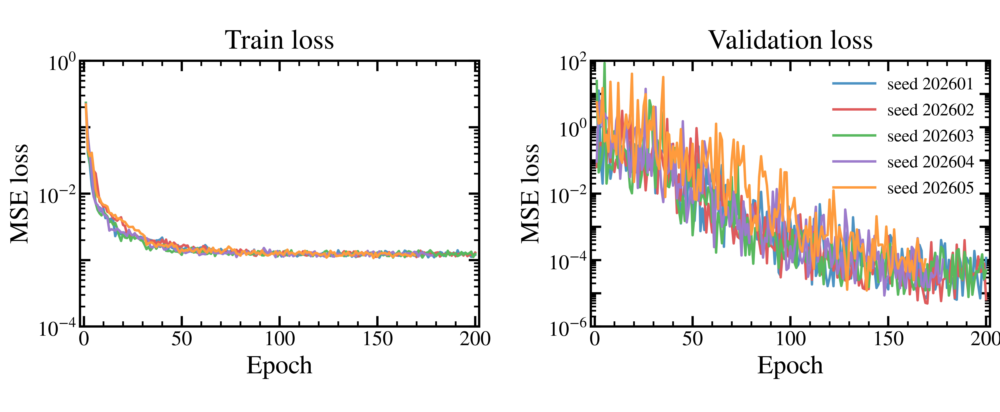

In [3]:
def format_even_decade(value: float, _position: float) -> str:
    exponent = int(round(np.log10(value)))
    return rf"$10^{{{exponent}}}$" if exponent % 2 == 0 else ""

def plot_loss() -> None:
    histories = {
        seed: json.loads((DATA / "gnn_training_histories" / f"seed{seed}.json").read_text())
        for seed in SEEDS
    }
    fig, (train_ax, val_ax) = plt.subplots(1, 2, figsize=(16, 6.6), facecolor="white")
    for seed, color in zip(SEEDS, LOSS_COLORS, strict=True):
        history = histories[seed]
        epoch = [item["epoch"] for item in history]
        train_ax.plot(epoch, [item["train_loss"] for item in history], color=COLORS[color], label=f"seed {seed}")
        val_ax.plot(epoch, [item["validation_loss"] for item in history], color=COLORS[color], label=f"seed {seed}")
    for ax, title, lower, upper in ((train_ax, "Train loss", 1e-4, 1), (val_ax, "Validation loss", 1e-6, 1e2)):
        ax.set(xlim=(-2, 202), ylim=(lower, upper), yscale="log", xlabel="Epoch", ylabel="MSE loss")
        ax.set_box_aspect(2 / 3)
        ax.set_title(title, fontsize=32, pad=14)
        style_axis(ax)
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
        ax.yaxis.set_major_formatter(FuncFormatter(format_even_decade))
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=100))
        ax.yaxis.set_minor_formatter(NullFormatter())
    val_ax.legend(loc="upper right", fontsize=20, handlelength=2.4, handletextpad=0.7)
    fig.subplots_adjust(left=0.08, right=0.99, bottom=0.18, top=0.88, wspace=0.28)
    publish(fig, OUT / "gnn_training_histories", tight=False)
    plt.close(fig)
plot_loss()


## Fig. 3: in-domain model comparison


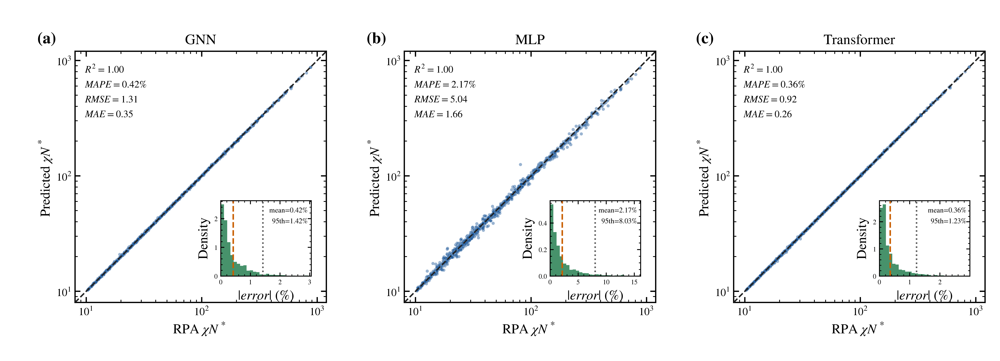

In [4]:
MODEL_ORDER = [("gnn", "GNN"),
               ("mlp", "MLP"),
               ("transformer", "Transformer")]
REPRESENTATIVE_SEED = 202604

with plt.rc_context({"font.size": 12, "axes.labelsize": 15,
                     "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "axes.titlesize": 16}):
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.6), facecolor="white")
    for panel, (model, label) in enumerate(MODEL_ORDER):
        ax = axes[panel]
        true, pred, _ = predictions[model, REPRESENTATIVE_SEED]
        result = metrics[(metrics.model == model) &
                         (metrics.seed == REPRESENTATIVE_SEED)].iloc[0]
        rel = np.abs(pred - true) / np.clip(np.abs(true), 1e-12, None) * 100
        mean_error = float(rel.mean())
        p95_error = float(np.percentile(rel, 95))
        upper = float(np.percentile(rel, 99.5))

        ax.scatter(true, pred, s=13, color=COLORS["parity_blue"], alpha=0.42,
                   edgecolors="white", linewidths=0.25, rasterized=True, zorder=2)
        ax.plot([8, 1200], [8, 1200], "--", color=COLORS["black"], lw=1.6, zorder=3)
        ax.set(xscale="log", yscale="log", xlim=(8, 1200), ylim=(8, 1200),
               xlabel=r"RPA $\chi N^*$", ylabel=r"Predicted $\chi N^*$")
        ax.set_box_aspect(1)
        ax.set_title(label, pad=8)
        ax.text(0.04, 0.96,
                "\n".join((rf"$R^2={result.R2:.2f}$",
                             rf"$MAPE={result.MAPE:.2f}\%$",
                             rf"$RMSE={result.RMSE:.2f}$",
                             rf"$MAE={result.MAE:.2f}$")),
                transform=ax.transAxes, ha="left", va="top", fontsize=11)
        style_axis(ax)
        ax.tick_params(axis="both", which="major", labelsize=12, length=6, width=1.4)
        ax.tick_params(axis="both", which="minor", length=3, width=0.9)
        for spine in ax.spines.values():
            spine.set_linewidth(1.4)

        inset = ax.inset_axes([0.58, 0.105, 0.36, 0.30])
        inset.hist(rel, bins=np.linspace(0, upper, 28), density=True,
                   color=COLORS["density_green"], alpha=0.82, edgecolor="none")
        inset.axvline(mean_error, color=COLORS["mean_orange"], ls="--", lw=1.7)
        inset.axvline(p95_error, color="0.35", ls=":", lw=1.7)
        inset.set(xlim=(0, upper * 1.04), xlabel=r"$|error|$ (%)", ylabel="Density")
        style_axis(inset)
        inset.tick_params(axis="both", which="major", labelsize=7.5, length=4, width=1.0)
        inset.tick_params(axis="both", which="minor", length=2, width=0.8)
        for spine in inset.spines.values():
            spine.set_linewidth(1.0)
        inset.text(0.96, 0.94, f"mean={mean_error:.2f}%\n95th={p95_error:.2f}%",
                   transform=inset.transAxes, ha="right", va="top", fontsize=8)

        ax.text(-0.15, 1.08, f"({chr(97 + panel)})", transform=ax.transAxes,
                fontsize=18, fontweight="bold", ha="left", va="top")

    fig.subplots_adjust(left=0.075, right=0.985, bottom=0.16, top=0.86, wspace=0.31)
    publish(fig, OUT / "in_domain_model_comparison", tight=False)


## Supplementary Fig. S3: all models and all in-domain seeds


In [5]:
MODEL_ROWS = [("gnn", "GNN"), ("mlp", "MLP"), ("transformer", "Transformer")]
with plt.rc_context({"font.size": 10, "axes.labelsize": 12,
                     "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "axes.titlesize": 12, "legend.fontsize": 10}):
    fig, axes = plt.subplots(3, 5, figsize=(18, 10.5), sharex=True, sharey=True)
    for row, (model, label) in enumerate(MODEL_ROWS):
        for column, seed in enumerate(SEEDS):
            ax = axes[row, column]
            true, pred, _ = predictions[model, seed]
            order = np.random.default_rng(seed).permutation(len(true))
            ax.scatter(true[order], pred[order], s=5,
                       color=COLORS["parity_blue"], alpha=0.42,
                       edgecolors="white", linewidths=0.2, rasterized=True)
            ax.plot([8, 1200], [8, 1200], "--", color="black", lw=1.2, zorder=5)
            ax.set(xscale="log", yscale="log", xlim=(8, 1200), ylim=(8, 1200))
            result = metrics[(metrics.model == model) & (metrics.seed == seed)].iloc[0]
            ax.text(0.04, 0.96,
                    rf"MAPE={result.MAPE:.3f}\%" + "\n" + rf"$R^2={result.R2:.4f}$",
                    transform=ax.transAxes, ha="left", va="top", fontsize=9,
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 1.5})
            style_axis(ax)
            ax.tick_params(axis="both", which="major", labelsize=9, length=5, width=1.2)
            ax.tick_params(axis="both", which="minor", length=2.5, width=0.9)
            for spine in ax.spines.values():
                spine.set_linewidth(1.2)
            if row == 0:
                ax.set_title(f"seed {seed}", pad=7)
            if row == 2:
                ax.set_xlabel(r"RPA $\chi N^*$")
        axes[row, 0].set_ylabel(f"{label}\nPredicted $\chi N^*$")
    fig.subplots_adjust(left=0.07, right=0.99, bottom=0.08, top=0.95, hspace=0.18, wspace=0.12)
    publish(fig, OUT / "in_domain_all_seed_parity", tight=True)


<>:30: SyntaxWarning: invalid escape sequence '\c'
<>:30: SyntaxWarning: invalid escape sequence '\c'
C:\Users\kachrel\AppData\Local\Temp\ipykernel_32112\1503162613.py:30: SyntaxWarning: invalid escape sequence '\c'
  axes[row, 0].set_ylabel(f"{label}\nPredicted $\chi N^*$")


## Supplementary Fig. S19: signed relative-error distributions for S15

Each panel shows $100(\hat y-y)/y$ for the same 2,000 seed-43 samples used in Supplementary Fig. S3. Errors retain their sign. Within each model row, all five panels use identical bins and axis limits spanning every observed error.


In [6]:
SIGNED_ERROR_ROWS = [("gnn", "GNN"), ("mlp", "MLP"), ("transformer", "Transformer")]

with plt.rc_context({"font.size": 10, "axes.labelsize": 12,
                     "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "axes.titlesize": 12}):
    fig, axes = plt.subplots(3, 5, figsize=(18, 10.5), facecolor="white")
    for row, (model, label) in enumerate(SIGNED_ERROR_ROWS):
        errors = {
            seed: (pred - true) / np.clip(np.abs(true), 1e-12, None) * 100
            for seed in SEEDS for true, pred, _ in [predictions[model, seed]]
        }
        limit = max(np.max(np.abs(values)) for values in errors.values()) * 1.04
        bins = np.linspace(-limit, limit, 41)
        ymax = max(np.histogram(values, bins=bins, density=True)[0].max() for values in errors.values()) * 1.08
        for column, seed in enumerate(SEEDS):
            ax = axes[row, column]
            values = errors[seed]
            mean, p5, p95 = np.mean(values), *np.percentile(values, [5, 95])
            ax.hist(values, bins=bins, density=True, color=COLORS["density_green"],
                    alpha=0.82, edgecolor="none")
            ax.axvline(0, color=COLORS["black"], lw=1.2)
            ax.axvline(mean, color=COLORS["mean_orange"], ls="--", lw=1.4)
            ax.axvline(p5, color="0.35", ls=":", lw=1.2)
            ax.axvline(p95, color="0.35", ls=":", lw=1.2)
            ax.set(xlim=(-limit, limit), ylim=(0, ymax))
            ax.text(0.96, 0.94, f"mean={mean:.2f}%\n5th={p5:.2f}%\n95th={p95:.2f}%",
                    transform=ax.transAxes, ha="right", va="top", fontsize=8.5,
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 1.2})
            style_axis(ax)
            ax.tick_params(axis="both", which="major", labelsize=9, length=5, width=1.2)
            ax.tick_params(axis="both", which="minor", length=2.5, width=0.9)
            for spine in ax.spines.values(): spine.set_linewidth(1.2)
            if row == 0: ax.set_title(f"seed {seed}", pad=7)
            if row == len(SIGNED_ERROR_ROWS) - 1: ax.set_xlabel("Relative error (%)")
        axes[row, 0].set_ylabel(f"{label}\nProbability density")
    fig.subplots_adjust(left=0.075, right=0.99, bottom=0.08, top=0.95, hspace=0.24, wspace=0.19)
    publish(fig, OUT / "in_domain_signed_relative_error", tight=True)
